# LLM-Based Sentiment Analysis (English + Turkish)
This notebook classifies the 3,000 texts in each of `en_dataset.csv` and `tr_dataset.csv` (1,000 Positive / 1,000 Negative / 1,000 Neutral) with a Large Language Model (LLM) using **zero-shot prompting**.

* **Provider:** Google Gemini (free tier) **or** Groq (free tier, Llama models). Both expose an OpenAI-compatible API, so the same code works for either.
* **Method:** Each request sends `BATCH_SIZE` texts as a numbered list; the model returns the labels as JSON. `temperature = 0` (deterministic).
* **Resumable:** Predictions are written to CSV after every request. If the daily quota runs out, re-run the cell later (or with another group member's API key) and it continues where it stopped.
* **Output:** `llm_en.csv`, `llm_tr.csv` (columns `text, label, pred`, same format as the BERT/VADER outputs) and `cm_llm_en.png`, `cm_llm_tr.png`.


## 1. Setup and API key
Add your key in Colab's left sidebar under **🔑 Secrets** with the name `GEMINI_API_KEY` (or `GROQ_API_KEY`). Gemini key: https://aistudio.google.com/apikey · Groq key: https://console.groq.com/keys

In [1]:
!pip -q install openai scikit-learn matplotlib pandas

PROVIDER = "gemini"   # "gemini" veya "groq"

import os, json, re, time
import pandas as pd
from openai import OpenAI

try:
    from google.colab import userdata
    KEY = userdata.get("GEMINI_API_KEY" if PROVIDER == "gemini" else "GROQ_API_KEY")
except Exception:
    from getpass import getpass
    KEY = getpass("API key: ")

BASE_URL = {
    "gemini": "https://generativelanguage.googleapis.com/v1beta/openai/",
    "groq":   "https://api.groq.com/openai/v1",
}[PROVIDER]
client = OpenAI(api_key=KEY, base_url=BASE_URL)
print("Connected:", PROVIDER)

Connected: gemini


## 2. Model selection
Lists the models available to your account. A **flash / flash-lite** model is recommended for Gemini, **llama-3.3-70b-versatile** for Groq. Record the chosen model name in the report.

In [3]:
names = sorted(m.id.replace("models/", "") for m in client.models.list())
print("\n".join(n for n in names if any(k in n for k in ["flash", "llama", "gemma", "qwen"])))

MODEL = "gemini-3.5-flash-lite"
print("Selected model:", MODEL)

gemini-2.5-flash
gemini-2.5-flash-image
gemini-2.5-flash-lite
gemini-2.5-flash-native-audio-latest
gemini-2.5-flash-native-audio-preview-09-2025
gemini-2.5-flash-native-audio-preview-12-2025
gemini-2.5-flash-preview-tts
gemini-3-flash-preview
gemini-3.1-flash-image
gemini-3.1-flash-image-preview
gemini-3.1-flash-lite
gemini-3.1-flash-lite-image
gemini-3.1-flash-lite-preview
gemini-3.1-flash-live-preview
gemini-3.1-flash-tts-preview
gemini-3.5-flash
gemini-3.5-flash-lite
gemini-3.6-flash
gemini-3.7-flash
gemini-3.8-flash
gemini-3.8-flash-lite-tts
gemini-3.8-flash-tts
gemini-flash-latest
gemini-flash-lite-latest
gemini-omni-1.1-flash
gemini-omni-1.2-flash
gemini-omni-flash-preview
gemma-4-26b-a4b-it
gemma-4-31b-it

Selected model: gemini-omni-flash-preview
Selected model: gemini-3.5-flash-lite


## 3. Load the data
Upload `en_dataset.csv` and `tr_dataset.csv`. For Turkish the **original Turkish text** is used, not the translation: LLMs are multilingual, so no translation step is needed.

In [4]:
from google.colab import files
if not (os.path.exists("en_dataset.csv") and os.path.exists("tr_dataset.csv")):
    files.upload()
en = pd.read_csv("en_dataset.csv")
tr = pd.read_csv("tr_dataset.csv")
print(en.label.value_counts(), tr.label.value_counts(), sep="\n")

Saving en_dataset.csv to en_dataset.csv
Saving tr_dataset.csv to tr_dataset.csv
label
Negative    1000
Positive    1000
Neutral     1000
Name: count, dtype: int64
label
Negative    1000
Positive    1000
Neutral     1000
Name: count, dtype: int64


## 4. Prompt design
Zero-shot, three explicitly defined classes and structured (JSON) output. The prompt is written in English and the same prompt is used for the Turkish texts, so the only variable between the two languages is the data.

In [5]:
LABELS = ["Positive", "Negative", "Neutral"]

SYSTEM_PROMPT = """You are an expert sentiment analysis annotator.
You will receive a numbered list of texts (customer reviews, tweets or sentences; they may be in English or Turkish).
Classify the overall sentiment of EACH text into exactly one of these labels:
- Positive: the author expresses satisfaction, praise, liking, gratitude or a favorable opinion.
- Negative: the author expresses dissatisfaction, complaint, criticism, anger, disappointment or an unfavorable opinion.
- Neutral: the text is factual, informational, a question, or expresses no clear positive or negative opinion.
Judge the author's attitude, not just individual words (handle negation, sarcasm and mixed statements by the overall tone).
Return ONLY a JSON object of the form {"results": [{"id": 1, "label": "Positive"}, ...]} with one entry per input text, in the same order."""

BATCH_SIZE = 25        # texts per request (raise to 50 if your daily quota is low)
MAX_CHARS  = 1500      # very long texts are truncated (saves tokens)
SLEEP_SEC  = 4.5       # pause between requests (stay under the requests-per-minute limit)

def build_user_msg(texts):
    lines = []
    for i, t in enumerate(texts, 1):
        t = re.sub(r"\s+", " ", str(t)).strip()[:MAX_CHARS]
        lines.append(f"{i}. {t}")
    return "Texts:\n" + "\n".join(lines)

def norm(lbl):
    l = str(lbl).strip().lower()
    if l.startswith("pos") or l.startswith("olumlu"): return "Positive"
    if l.startswith("neg") or l.startswith("olumsuz"): return "Negative"
    if l.startswith("neu") or l.startswith("nöt") or l.startswith("not"): return "Neutral"
    return None

def classify_batch(texts, retries=6):
    for attempt in range(retries):
        try:
            r = client.chat.completions.create(
                model=MODEL, temperature=0,
                response_format={"type": "json_object"},
                messages=[{"role": "system", "content": SYSTEM_PROMPT},
                          {"role": "user", "content": build_user_msg(texts)}])
            raw = r.choices[0].message.content
            m = re.search(r"\{.*\}", raw, re.S)
            res = json.loads(m.group(0))["results"]
            preds = {int(x["id"]): norm(x["label"]) for x in res}
            out = [preds.get(i) for i in range(1, len(texts) + 1)]
            if all(out):
                return out
            raise ValueError(f"missing/invalid labels: {out}")
        except Exception as e:
            msg = str(e)
            if "429" in msg or "RESOURCE_EXHAUSTED" in msg or "rate" in msg.lower():
                if "per day" in msg.lower() or "PerDay" in msg:
                    raise RuntimeError("DAILY QUOTA EXHAUSTED. Re-run later or with another API key; it resumes where it stopped.") from e
                wait = 20 * (attempt + 1)
            else:
                wait = 5
            print(f"  error ({type(e).__name__}): {msg[:150]} -> waiting {wait}s")
            time.sleep(wait)
    # if a batch keeps failing, split it in half and retry
    if len(texts) > 1:
        h = len(texts) // 2
        return classify_batch(texts[:h]) + classify_batch(texts[h:])
    return ["Neutral"]   # fallback if a single text cannot be classified at all (mention in report)

# Quick test
print(classify_batch(["I love this airline!", "Bu ürün tam bir hayal kırıklığı.", "Ankara Türkiye'nin başkentidir."]))

['Positive', 'Negative', 'Neutral']


## 5. Generate predictions (resumable)

In [7]:
def run(df, out_path):
    if os.path.exists(out_path):
        done = pd.read_csv(out_path)
    else:
        done = df[["text", "label"]].copy(); done["pred"] = None
    todo = done.index[done.pred.isna()].tolist()
    print(f"{out_path}: {len(done) - len(todo)} done, {len(todo)} remaining")
    for s in range(0, len(todo), BATCH_SIZE):
        idx = todo[s:s + BATCH_SIZE]
        done.loc[idx, "pred"] = classify_batch(done.loc[idx, "text"].tolist())
        done.to_csv(out_path, index=False)
        print(f"  {s + len(idx)}/{len(todo)}", end="\r")
        time.sleep(SLEEP_SEC)
    print(f"\n{out_path} completed.")
    return done

llm_en = run(en, "llm_en.csv")

llm_en.csv: 2225 done, 775 remaining
  error (InternalServerError): Error code: 503 - [{'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Pleas -> waiting 5s
  error (InternalServerError): Error code: 503 - [{'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Pleas -> waiting 5s

llm_en.csv completed.


In [8]:
llm_tr = run(tr, "llm_tr.csv")

llm_tr.csv: 0 done, 3000 remaining
  error (InternalServerError): Error code: 503 - [{'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Pleas -> waiting 5s
  error (ValueError): missing/invalid labels: ['Positive', 'Negative', 'Positive', 'Neutral', 'Positive', 'Neutral', 'Positive', 'Positive', 'Positive', 'Neutral', 'Negativ -> waiting 5s
  error (ValueError): missing/invalid labels: ['Positive', 'Positive', 'Positive', None, 'Negative', 'Negative', 'Positive', 'Negative', 'Neutral', 'Negative', 'Negative',  -> waiting 5s
  error (InternalServerError): Error code: 503 - [{'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Pleas -> waiting 5s
  error (InternalServerError): Error code: 503 - [{'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Pleas -> waiting 5s
  e

## 6. Evaluation: confusion matrix and per-class misclassification counts

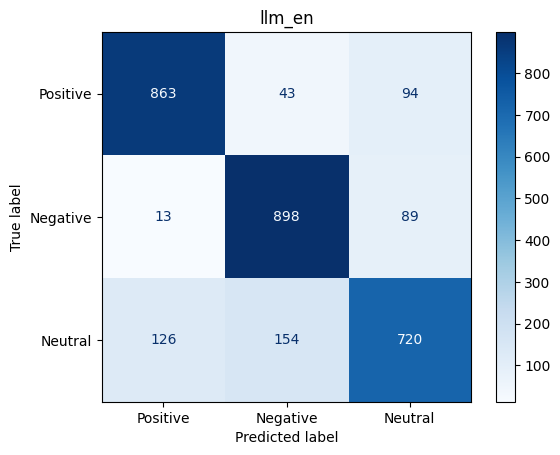

              precision    recall  f1-score   support

    Positive     0.8613    0.8630    0.8621      1000
    Negative     0.8201    0.8980    0.8573      1000
     Neutral     0.7973    0.7200    0.7567      1000

    accuracy                         0.8270      3000
   macro avg     0.8262    0.8270    0.8254      3000
weighted avg     0.8262    0.8270    0.8254      3000

Misclassification counts: {'Positive': 137, 'Negative': 102, 'Neutral': 280} | Total: 519


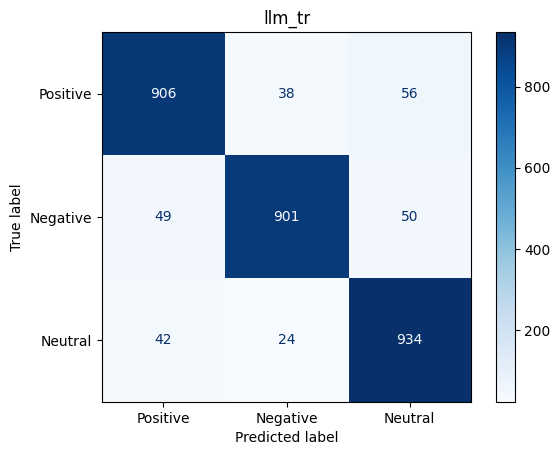

              precision    recall  f1-score   support

    Positive     0.9087    0.9060    0.9074      1000
    Negative     0.9356    0.9010    0.9180      1000
     Neutral     0.8981    0.9340    0.9157      1000

    accuracy                         0.9137      3000
   macro avg     0.9141    0.9137    0.9137      3000
weighted avg     0.9141    0.9137    0.9137      3000

Misclassification counts: {'Positive': 94, 'Negative': 99, 'Neutral': 66} | Total: 259


{'Positive': 94, 'Negative': 99, 'Neutral': 66}

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

def evaluate(df, name):
    cm = confusion_matrix(df.label, df.pred, labels=LABELS)
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap="Blues", values_format="d")
    plt.title(name); plt.savefig(f"cm_{name}.png", dpi=150, bbox_inches="tight"); plt.show()
    print(classification_report(df.label, df.pred, labels=LABELS, digits=4))
    errors = {l: int(((df.label == l) & (df.pred != l)).sum()) for l in LABELS}
    print("Misclassification counts:", errors, "| Total:", sum(errors.values()))
    return errors

evaluate(llm_en, "llm_en")
evaluate(llm_tr, "llm_tr")

## 7. Download results

In [10]:
for f in ["llm_en.csv", "llm_tr.csv", "cm_llm_en.png", "cm_llm_tr.png"]:
    if os.path.exists(f): files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>